In [4]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import statsmodels.formula.api as smf
from itertools import product
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay,
)
from itertools import combinations
from scipy import sparse
from threadpoolctl import threadpool_limits

SEED = 42
SAMPLE_FRACTION = 0.0005  # 0.05%
DATA_PATH = "datasets/USDOT_1987_2025_Flights_Dataset/flights_2008_2025_cleaned.parquet"

Our data from 2008-2025 is about 1.5M entries. To enable effective modelling we sampled only 0.05% of it. Using a SEED to ensure reproducibility.

In [5]:
parquet = pq.ParquetFile(DATA_PATH)
sample_size = round(parquet.metadata.num_rows * SAMPLE_FRACTION)
rng = np.random.default_rng(SEED)
positions = np.sort(rng.choice(parquet.metadata.num_rows, sample_size, replace=False))

parts = []
offset = 0
for group in range(parquet.num_row_groups):
    end = offset + parquet.metadata.row_group(group).num_rows
    rows = positions[(positions >= offset) & (positions < end)] - offset
    if len(rows):
        table = parquet.read_row_group(group)
        parts.append(table.take(rows).to_pandas())
    offset = end
data = pd.concat(parts, ignore_index=True)
print(f"Sample: {len(data):,} flights")

Sample: 57,181 flights


To better understand the features are grouped into different categories:
- Calendar                                
- Scheduled flight information            
- Realized departure operations           
- Realized flight/arrival operations      
- Primary outcomes / possible targets     
- Disruption details and delay attribution

The table bellow groups these features into those categories:

The groups below distinguish variables known before departure from fields created during or after the flight. This matters because using a field that is unavailable at prediction time causes **target leakage**.

| Category                                 | Columns                                                                                                                                                                                               |
|------------------------------------------|-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Calendar                                 | `year`, `month`, `day`, `formatted_date`, `dayofweek`                                                                                                                                                 |
| Scheduled flight information             | `airline`, `iata_code_reporting_airline`, `flight_number`, `tail_number`, `origin_airport_id`, `dest_airport_id`, `crs_dep_time_hhmm`, `scheduled_arrival_hhmm`, `scheduled_elapsed_time`, `distance` |
| Realized departure operations            | `departure_time_hhmm`, `departure_delay`, `departure_delay_mins`, `taxi_out`, `wheels_off_hhmm`                                                                                                       |
| Realized flight/arrival operations       | `elapsed_time`, `air_time`, `wheels_on_hhmm`, `taxi_in`, `arrival_time_hhmm`                                                                                                                          |
| Primary outcomes / possible targets      | `arrival_delay`, `arrival_delay_mins`, `cancelled`, `diverted, departure_delay`                                                                                                                                        |
| Disruption details and delay attribution | `cancellation_code`, `airline_delay`, `weather_delay`, `air_system_delay`, `security_delay`, `late_aircraft_delay`, `div_reached_dest`, `div_actual_elapsed_time`                                     |

The target that will be used will be Arrival Delay. For reference, the USDOT clasifies a flight that arrives 15 minutes past its scheduled time as delayed. 

Our Moderl objective will be to Predict a flight arrival delay using only information available before the flight departs.

Selecting features

For our model we have to select features that are knnown before the flight occurs these are:

- Month
- Year
- DayofWeek
- Airline
- Distance
- Origin Airport
- Destination Airport 
- Scheduled Departure Time 
- Scheduled Elapsed Time
- Scheduled Arival Time 



In [6]:
sample = data.loc[(data["cancelled"] == 0) & (data["diverted"] == 0)].copy()
numeric = ["distance", "scheduled_elapsed_time"]
print(f"Eligible: {len(sample):,}; excluded: {len(data) - len(sample):,}")
sample[numeric].describe().round(2)

Eligible: 55,980; excluded: 1,201


,distance,scheduled_elapsed_time
count,55980.00,55980.00
mean,796.03,139.33
std,592.28,72.72
min,31.00,21.00
25%,363.00,86.00
50%,632.00,120.00
75%,1028.00,170.00
max,4983.00,680.00


Since `crs_dep_time_hhmm` and `scheduled_arrival_hhmm` are stored in HH:MM format, we need to convert these columns into numerical representations to facilitate data visualization and statistical analysis.

We will convert each time into the **number of minutes elapsed since midnight**. For example, 00:00 will correspond to 0 minutes, 06:00 to 360 minutes, and 12:00 to 720 minutes.

Special consideration must be given to flights that cross midnight, particularly those arriving on the following calendar day. Since this conversion only represents the time of day, it does not account for changes in calendar date or differences between airport time zones. These factors will need to be considered separately when calculating elapsed time or comparing departure and arrival times.

In [7]:
def hhmm_to_minutes(series):
    # Convert values to strings and remove colons
    times = (
        series.astype("string")
        .str.strip()
        .str.replace(":", "", regex=False)
    )

    # Convert HHMM strings into numbers
    times = pd.to_numeric(times, errors="coerce")

    # Extract hours and minutes
    hours = times // 100
    minutes = times % 100

    # Check for valid time values
    valid = (
        hours.between(0, 23)
        & minutes.between(0, 59)
    )

    # Convert to minutes since midnight
    total_minutes = hours * 60 + minutes

    return total_minutes.where(valid)

In [8]:
sample['scheduled_arrival_minutes'] = hhmm_to_minutes(sample['scheduled_arrival_hhmm'])
sample['crs_dep_time_minutes'] = hhmm_to_minutes(sample['crs_dep_time_hhmm'])
sample.drop('crs_dep_time_hhmm', axis=1, inplace=True)
sample.drop('scheduled_arrival_hhmm', axis=1, inplace=True)

In [9]:
sample[['scheduled_arrival_minutes', 'crs_dep_time_minutes', 'scheduled_elapsed_time']].describe()

,scheduled_arrival_minutes,crs_dep_time_minutes,scheduled_elapsed_time
count,55980.0,55980.0,55980.000000
mean,907.693408,807.324795,139.333244
std,301.813356,289.424628,72.720772
min,1.0,4.0,21.000000
25%,670.0,555.0,86.000000
50%,920.0,800.0,120.000000
75%,1155.0,1050.0,170.000000
max,1439.0,1439.0,680.000000


Since we have a separate DataFrame containing the airport IDs and their corresponding airport codes, we will map the numerical airport IDs to their respective airport codes. This will make the data easier to interpret and allow us to treat airports as categorical features in our regression analysis, rather than continuous numerical variables.

In [10]:
airport_df = pd.read_csv('datasets/USDOT_1987_2025_Flights_Dataset/airports.csv')
airport_df = airport_df[['airport_id', 'airport_code']]

airport_dict = (
    airport_df
    .set_index("airport_id")["airport_code"]
    .to_dict()
)
sample['origin_airport'] = sample['origin_airport_id'].map(airport_dict)
sample['dest_airport'] = sample['dest_airport_id'].map(airport_dict)
sample.drop('dest_airport_id', axis=1, inplace=True)
sample.drop('origin_airport_id', axis=1, inplace=True)



In [11]:
airline_df = pd.read_csv('datasets/USDOT_1987_2025_Flights_Dataset/airlines.csv')
airline_df = airline_df[['IATA_CODE_Reporting_Airline', 'airline_name']]

airline_dict = (
    airline_df
    .set_index("IATA_CODE_Reporting_Airline")["airline_name"]
    .to_dict()
)

sample['airline_name'] = sample['airline'].map(airline_dict)
sample['airline_name'] = sample['airline_name'].str.title()

We now drop the remaining columns not being used

In [12]:
features = [
    'month', 
    'year', 
    'dayofweek', 
    'airline', 
    'origin_airport', 
    'distance', 
    'dest_airport', 
    'crs_dep_time_minutes', 
    'scheduled_elapsed_time', 
    'scheduled_arrival_minutes']


target = "arrival_delay"

model_data = sample[features + [target]].copy()


In [13]:
model_data.describe()

,month,year,dayofweek,distance,crs_dep_time_minutes,scheduled_elapsed_time,scheduled_arrival_minutes,arrival_delay
count,55980.0,55980.0,55980.0,55980.000000,55980.0,55980.000000,55980.0,55980.000000
mean,6.550286,2016.577653,3.964255,796.029064,807.324795,139.333244,907.693408,4.932226
std,3.414916,5.304018,1.998586,592.281419,289.424628,72.720772,301.813356,45.542321
min,1.0,2008.0,1.0,31.000000,4.0,21.000000,1.0,-80.000000
25%,4.0,2012.0,2.0,363.000000,555.0,86.000000,670.0,-14.000000
50%,7.0,2017.0,4.0,632.000000,800.0,120.000000,920.0,-5.000000
75%,9.0,2021.0,6.0,1028.000000,1050.0,170.000000,1155.0,8.000000
max,12.0,2025.0,7.0,4983.000000,1439.0,680.000000,1439.0,1740.000000


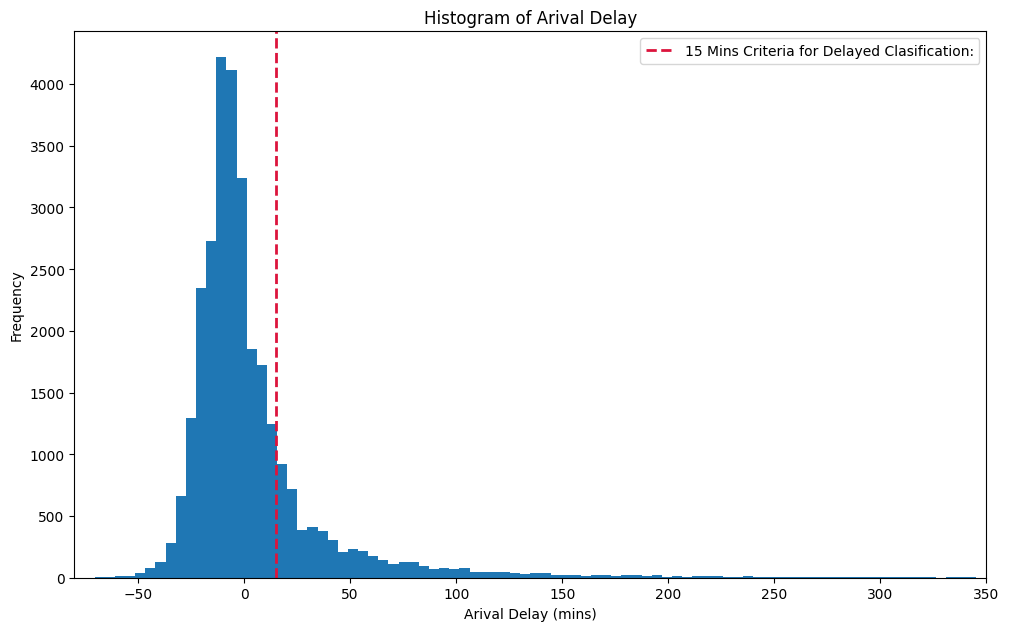

In [69]:

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(model_data['arrival_delay'], bins=300)
plt.xlim(min(model_data['arrival_delay']),350)
ax.axvline(
    15,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"15 Mins Criteria for Delayed Clasification:")

plt.tight_layout()
plt.legend()
plt.ylabel('Frequency')
plt.xlabel('Arival Delay (mins)')
plt.title('Histogram of Arival Delay')
plt.show()


## Multicollinearity

Now we review our features to asses multicolinearity

In [15]:
numerical_features = [
    "crs_dep_time_minutes",
    "scheduled_arrival_minutes",
    "scheduled_elapsed_time",
    'distance'
]

correlation_matrix = model_data[numerical_features].corr()

display(correlation_matrix)

,crs_dep_time_minutes,scheduled_arrival_minutes,scheduled_elapsed_time,distance
crs_dep_time_minutes,1.000000,0.723752,-0.020689,-0.014828
scheduled_arrival_minutes,0.723752,1.000000,0.030562,0.025950
scheduled_elapsed_time,-0.020689,0.030562,1.000000,0.983119
distance,-0.014828,0.025950,0.983119,1.000000


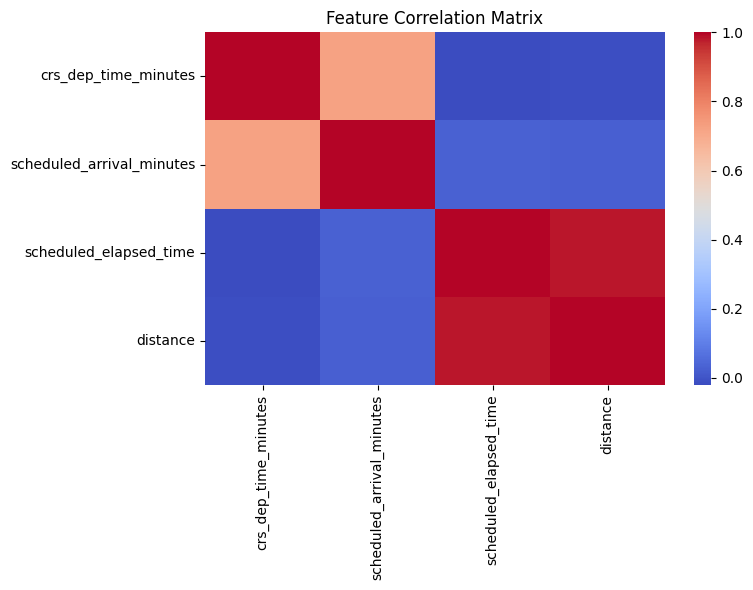

In [16]:
correlation_matrix = model_data[numerical_features].corr()

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    correlation_matrix, cmap = "coolwarm")

ax.set_title("Feature Correlation Matrix")

plt.tight_layout()
plt.show()

In [17]:
X = model_data[numerical_features]
X = X.astype("float64")

# Include an intercept
X = sm.add_constant(X)
vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns

vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]

# Exclude intercept and sort by VIF
vif_data = (
    vif_data[vif_data["Feature"] != "const"]
    .sort_values("VIF", ascending=False)
)

display(vif_data)

,Feature,VIF
3,scheduled_elapsed_time,30.075056
4,distance,30.022654
2,scheduled_arrival_minutes,2.117967
1,crs_dep_time_minutes,2.117756


### Multicollinearity Analysis — Numerical Features

Following the correlation analysis, Variance Inflation Factors (VIF) were calculated to investigate multicollinearity among the numerical predictors.

The results revealed substantial multicollinearity between Scheduled Elapsed Time and Distance, with VIF values of 30.08 and 30.02, respectively. These findings are consistent with their strong positive Pearson correlation (r = 0.9831), indicating that the two variables contain considerable overlapping information.

In contrast, Scheduled Departure Time and Scheduled Arrival Time returned VIF values of 2.18 and 2.12, respectively, indicating relatively manageable multicollinearity.

Based on these findings, no predictors will be automatically excluded at this stage. Instead, the potential redundancy between Scheduled Elapsed Time and Distance will be investigated during BIC model selection to determine whether including both variables provides sufficient improvement in model fit to justify their inclusion.

In [18]:
categorical_features = [
    'month', 
    'year', 
    'dayofweek', 
    'airline', 
    'origin_airport', 
    'dest_airport', ]

model_data[categorical_features].nunique()

month              12
year               18
dayofweek           7
airline            25
origin_airport    375
dest_airport      370
dtype: int64

### Restricting the Analysis to the Busiest Origin Airports

To reduce model complexity and focus our analysis on higher-traffic airports, we restricted the dataset to flights originating from the 20 busiest airports, based on flight counts within our sample. For the destination airports we will group them, each major airport will be its own group while the rest will be grouped into "Other"

This reduced the dataset from 55,980 to 29,615 observations, retaining approximately 52.9% of the original data. The number of unique origin airports decreased from 375 to 20, while the dataset still contains 339 unique destination airports.

This approach substantially reduces the number of parameters required to represent origin airports through one-hot encoding. However, it also limits the scope of our findings to flights originating from these 20 airports, rather than the entire airport network.

In [19]:
top_20_origins = (
    model_data["origin_airport"]
    .value_counts()
    .head(20)
    .index
)

display(
    model_data["origin_airport"]
    .value_counts()
    .head(20)
)

origin_airport
ATL    3275
ORD    2595
DFW    2323
DEN    2129
LAX    1766
PHX    1598
LAS    1438
CLT    1382
IAH    1351
SFO    1251
DTW    1208
SEA    1159
MSP    1101
MCO    1093
LGA    1069
SLC    1033
BOS    1022
EWR     993
JFK     975
DCA     854
Name: count, dtype: int64

In [20]:
model_data_top20 = model_data.loc[
    model_data["origin_airport"].isin(top_20_origins)
].copy()

In [21]:
print("Original observations:", len(model_data))
print("Filtered observations:", len(model_data_top20))

print(
    "Percentage retained:",
    round(len(model_data_top20) / len(model_data) * 100, 2),
    "%"
)

print(
    "Unique origins:",
    model_data_top20["origin_airport"].nunique()
)

print(
    "Unique destinations:",
    model_data_top20["dest_airport"].nunique()
)

Original observations: 55980
Filtered observations: 29615
Percentage retained: 52.9 %
Unique origins: 20
Unique destinations: 339


In [22]:
top_20_dest = (
    model_data["dest_airport"]
    .value_counts()
    .head(20)
    .index
)

display(
    model_data["dest_airport"]
    .value_counts()
    .head(20)
)

dest_airport
ATL    3189
ORD    2612
DFW    2303
DEN    2269
LAX    1842
PHX    1535
CLT    1457
LAS    1366
IAH    1321
SFO    1277
DTW    1206
MCO    1131
SEA    1116
MSP    1078
EWR    1053
LGA    1052
SLC    1028
BOS    1025
JFK     927
DCA     858
Name: count, dtype: int64

In [23]:
model_data = model_data.loc[
    model_data["origin_airport"].isin(top_20_origins)
]

In [24]:
model_data["dest_airport_group"] = np.where(
    model_data["dest_airport"].isin(top_20_dest),
    model_data["dest_airport"],
    "Other"
)

By limiting our analysis to the 20 busiest origin airports and grouping destinations into the 20 busiest airports plus an "Other" category, we have significantly reduced the number of categorical variables that will be introduced during one-hot encoding.

This approach allows us to retain 29,615 observations, representing approximately 52.9% of our original dataset, while reducing the complexity associated with airport features. Our categorical predictors now consist of 102 categories, requiring 96 dummy variables when using one-hot encoding with a reference category omitted for each feature.

In [25]:
categorical_features = [
    'month', 
    'year', 
    'dayofweek', 
    'airline', 
    'origin_airport', 
    'dest_airport_group', ]

model_data[categorical_features].nunique()

month                 12
year                  18
dayofweek              7
airline               24
origin_airport        20
dest_airport_group    21
dtype: int64

In [26]:
final_features =[
    'distance', 
    'crs_dep_time_minutes', 
    'scheduled_elapsed_time', 
    'scheduled_arrival_minutes',    
    'month', 
    'year', 
    'dayofweek', 
    'airline', 
    'origin_airport', 
    'dest_airport_group']

In [27]:
sample['routes'] = sample['origin_airport'] + "-" + sample['dest_airport']

Lets see what happen if when we do a multiple linear regression with the features we selected and no polynomial terms:


$\text{Arrival Delay}(Y) = \beta_0 + \beta_1T_D +\sum_{j=1}^{p}\gamma_j C_j + \beta_2T_A + \beta_3T_E + \beta_4D$

Where:

$T_D$: Scheduled Departure Time


$T_A$: Scheduled Arrival Time


$T_E$: Scheduled Ellapsed TIme


$D$: Distance


$p$: Total number of categorical dummy variables.



$j$: Index identifying each dummy variable, from 1 to \(p\).



$\gamma_j$: Regression coefficient associated with dummy variable \(j\).



$C_j$: Dummy variable indicating whether an observation belongs to a particular category (0 or 1).

In [28]:
numerical_features = [
    "crs_dep_time_minutes",
    "scheduled_arrival_minutes",
    "scheduled_elapsed_time",
    'distance'
]
categorical_features = [
    'month', 
    'year', 
    'dayofweek', 
    'airline', 
    'origin_airport', 
    'dest_airport_group', ]

TARGET = 'arrival_delay'
independent_variables = numerical_features + categorical_features

X = model_data[independent_variables].copy()
y = model_data[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
)

In [63]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical_onehot", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features),
        ("numerical", 'passthrough', numerical_features),
    ],
    remainder="drop",
)

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regression", LinearRegression()),
    ]
)
model_linear = linear_model.fit(X_train, y_train)
model_linear

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical_onehot', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the

In [64]:
y_pred = linear_model.predict(X_test)

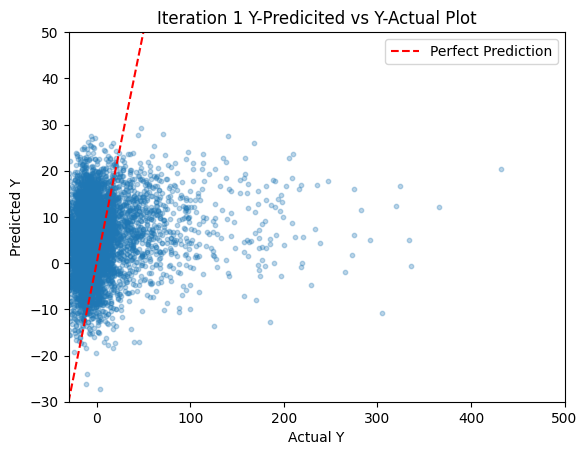

In [72]:
import matplotlib.pyplot as plt
import numpy as np

plt.scatter(y_test, y_pred, alpha=0.3, s=10)

# Perfect prediction reference line
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], 'r--', label='Perfect Prediction')

plt.xlabel("Actual Y")
plt.ylabel("Predicted Y")
plt.xlim(-30, 500)
plt.ylim(-30, 50)
plt.title('Iteration 1 Y-Predicited vs Y-Actual Plot')
plt.legend()
plt.show()

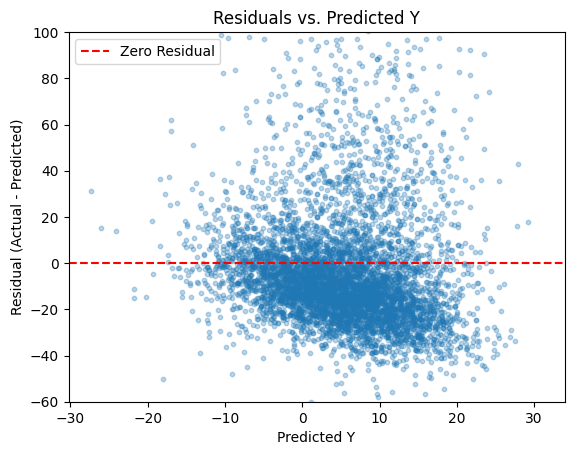

In [ ]:
residuals = y_test - y_pred

plt.scatter(y_pred, residuals, alpha=0.3, s=10)
plt.axhline(y=0, color='r', linestyle='--', label='Zero Residual')
plt.xlabel("Predicted Y")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs. Predicted Y")
plt.ylim(-60,100)
plt.legend()
plt.show()

In [33]:
#Mean baseline
y_baseline = np.full(len(y_test), y_train.mean())

# Compare models
results = pd.DataFrame({
    "Model": ["Mean Baseline", "Linear Regression"],
    "RMSE": [
        root_mean_squared_error(y_test, y_baseline),
        root_mean_squared_error(y_test, y_pred)
    ],
    "RMAE": [
        mean_absolute_error(y_test, y_baseline),
        mean_absolute_error(y_test, y_pred)
    ],
    "R²": [
        r2_score(y_test, y_baseline),
        r2_score(y_test, y_pred)
    ]
})

display(results.round(4))

,Model,RMSE,RMAE,R²
0,Mean Baseline,38.0682,22.0662,-0.0005
1,Linear Regression,37.6013,21.8690,0.0239


In [34]:


def model_results(model, X_test, y_test):
    model = model
    X_eval = X_test.copy()
    cols = X_eval.select_dtypes(include=["Int8", "Int16", "Int32", "Int64"]).columns
    X_eval[cols] = X_eval[cols].astype("float64")

    y_pred = np.asarray(model.predict(X_eval)).ravel()
    y_actual = np.asarray(y_test).ravel()

    typical_mask = (y_actual >= -30) & (y_actual <= 30)
    extreme_mask = ~typical_mask

    y_typical = y_actual[typical_mask]
    pred_typical = y_pred[typical_mask]

    y_extreme = y_actual[extreme_mask]
    pred_extreme = y_pred[extreme_mask]

    return y_pred, y_actual, y_typical, pred_typical, y_extreme, pred_extreme

# Reusable plotting function
def plot_predictions(ax, actual, predicted, title, limits=None):

    # Calculate performance metrics using all supplied observations
    mae = mean_absolute_error(actual, predicted)
    rmse = root_mean_squared_error(actual, predicted)
    r2 = r2_score(actual, predicted)

    # Scatter plot
    ax.scatter(actual, predicted, alpha=0.3, s=10)

    # Determine axis limits
    if limits is None:
        low = min(actual.min(), predicted.min())
        high = max(actual.max(), predicted.max())

        low = np.floor(low / 50) * 50
        high = np.ceil(high / 50) * 50
    else:
        low, high = limits

    # Perfect prediction reference line
    ax.plot(
        [low, high],
        [low, high],
        "r--",
        label="Perfect Prediction"
    )

    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_aspect("equal", adjustable="box")

    # Title and metrics
    ax.set_title(
        f"{title}\n"
        f"MAE: {mae:.3f} | RMSE: {rmse:.3f} | R²: {r2:.4f}"
    )

    ax.set_xlabel("Actual Arrival Delay (min)")
    ax.set_ylabel("Predicted Arrival Delay (min)")
    ax.grid(alpha=0.2)
    ax.legend()




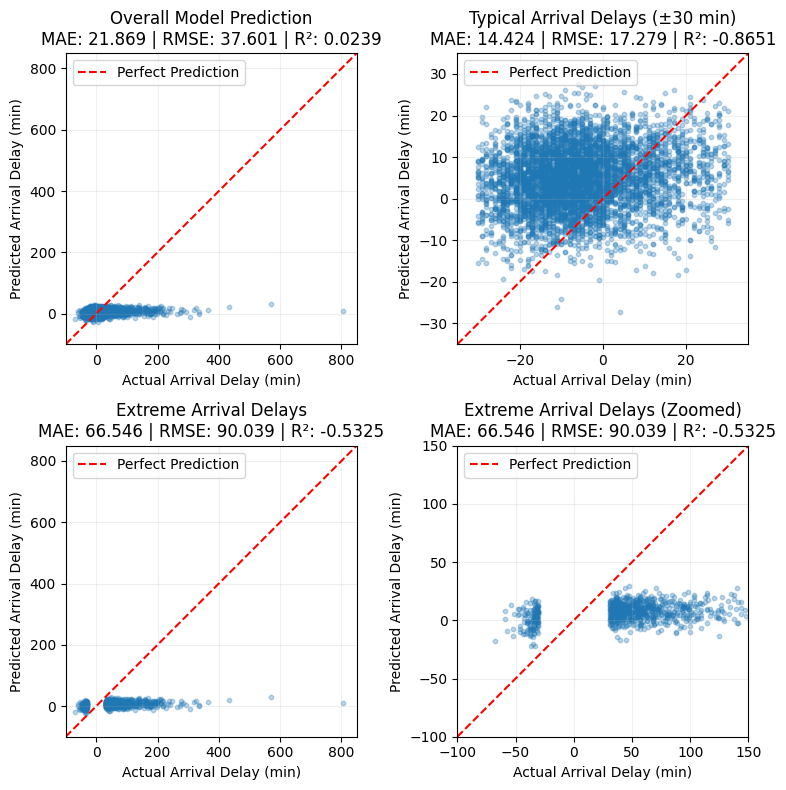

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(8, 8))

y_pred, y_actual, y_typical, pred_typical, y_extreme, pred_extreme = model_results(model_linear, X_test, y_test)

# 1. Overall model prediction
plot_predictions(
    axes[0, 0],
    y_actual,
    y_pred,
    "Overall Model Prediction"
)

# 2. Typical delays (+/- 30 minutes)
plot_predictions(
    axes[0, 1],
    y_typical,
    pred_typical,
    "Typical Arrival Delays (±30 min)",
    limits=(-35, 35)
)

# 3. Extreme delays
plot_predictions(
    axes[1, 0],
    y_extreme,
    pred_extreme,
    "Extreme Arrival Delays"
)

# 4. Zoomed-in extreme delays
plot_predictions(
    axes[1, 1],
    y_extreme,
    pred_extreme,
    "Extreme Arrival Delays (Zoomed)",
    limits=(-100, 150)
)

plt.tight_layout()
plt.show()

From our results, we observe a substantial reduction in both MAE and RMSE when evaluating our model on flights with arrival delays between −30 and +30 minutes.

| Model Evaluation | RMSE (min) | MAE (min) | R² |
|---|---:|---:|---:|
|Baseline| 38.0682|22.0662|-0.0005|
| All Delays | 37.601 | 21.869 | 0.0239 |
| Typical Delays (±30 min) | 17.279 | 14.424 | -0.8651 |
| Extreme Delays (outside ±30 min) | 90.039 | 66.546 | -0.5325 |

An example of a regression model incorporating a second-order polynomial term is:

$$
\text{Arrival Delay}(Y) = \beta_0 + \beta_1T_D + \sum_{j=1}^{p}\gamma_j C_j + \beta_2T_A + \beta_3T_E + \beta_4D + \beta_5D^2
$$

In this example, our **distance feature (D)** is assigned a polynomial degree of 2. By including both the linear and squared distance terms, we allow the model to capture a potential nonlinear relationship between flight distance and arrival delays.

In [36]:
numerical_features = [
    "crs_dep_time_minutes",
    "scheduled_arrival_minutes",
    "scheduled_elapsed_time",
    'distance'
]

degrees = [1, 2, 3]

degree_comb = list(product(degrees, repeat=len(numerical_features)))

print(degree_comb)
print(f"Total combinations: {len(degree_comb)}")

[(1, 1, 1, 1), (1, 1, 1, 2), (1, 1, 1, 3), (1, 1, 2, 1), (1, 1, 2, 2), (1, 1, 2, 3), (1, 1, 3, 1), (1, 1, 3, 2), (1, 1, 3, 3), (1, 2, 1, 1), (1, 2, 1, 2), (1, 2, 1, 3), (1, 2, 2, 1), (1, 2, 2, 2), (1, 2, 2, 3), (1, 2, 3, 1), (1, 2, 3, 2), (1, 2, 3, 3), (1, 3, 1, 1), (1, 3, 1, 2), (1, 3, 1, 3), (1, 3, 2, 1), (1, 3, 2, 2), (1, 3, 2, 3), (1, 3, 3, 1), (1, 3, 3, 2), (1, 3, 3, 3), (2, 1, 1, 1), (2, 1, 1, 2), (2, 1, 1, 3), (2, 1, 2, 1), (2, 1, 2, 2), (2, 1, 2, 3), (2, 1, 3, 1), (2, 1, 3, 2), (2, 1, 3, 3), (2, 2, 1, 1), (2, 2, 1, 2), (2, 2, 1, 3), (2, 2, 2, 1), (2, 2, 2, 2), (2, 2, 2, 3), (2, 2, 3, 1), (2, 2, 3, 2), (2, 2, 3, 3), (2, 3, 1, 1), (2, 3, 1, 2), (2, 3, 1, 3), (2, 3, 2, 1), (2, 3, 2, 2), (2, 3, 2, 3), (2, 3, 3, 1), (2, 3, 3, 2), (2, 3, 3, 3), (3, 1, 1, 1), (3, 1, 1, 2), (3, 1, 1, 3), (3, 1, 2, 1), (3, 1, 2, 2), (3, 1, 2, 3), (3, 1, 3, 1), (3, 1, 3, 2), (3, 1, 3, 3), (3, 2, 1, 1), (3, 2, 1, 2), (3, 2, 1, 3), (3, 2, 2, 1), (3, 2, 2, 2), (3, 2, 2, 3), (3, 2, 3, 1), (3, 2, 3, 2), (3, 2

In [37]:
hot_code = []
cat_formula = []
for cat in categorical_features:
    hot_code.append(f'C({cat})')
cat_formula.append(" + ".join(hot_code))
models = []
for combs in degree_comb:
    formula_terms = []

    for feature, degree in zip(numerical_features, combs):
        for power in range(1, degree + 1):
            if power == 1:
                formula_terms.append(feature)
            else:
                formula_terms.append(f"I({feature}**{power})")

    models.append(" + ".join(formula_terms + cat_formula))

In [38]:
results = []
train_df = pd.concat([X_train, y_train], axis=1)
test_df = pd.concat([X_test, y_test], axis=1)


for df in [train_df, test_df]:
    cols = df.select_dtypes(include=["Int8", "Int16", "Int32", "Int64"]).columns
    df[cols] = df[cols].astype("float64")

fitted_models = []
    
for i, (formula, combs) in enumerate(zip(models, degree_comb)):

    model = smf.ols(
        formula=f"arrival_delay ~ {formula}",
        data=train_df
    ).fit()
    fitted_models.append(model)
    predictions = model.predict(test_df)
    actual = test_df["arrival_delay"]

    results.append({
        "model_id": i,
        **dict(zip(numerical_features, combs)),
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": root_mean_squared_error(actual, predictions),
        "R2": r2_score(actual, predictions)
    })

results_df = pd.DataFrame(results)

In [39]:
display(results_df.sort_values('RMSE', ascending=True).head(5))
display(results_df.sort_values('MAE', ascending=True).head(5))
display(results_df.sort_values('R2', ascending=False).head(5))

,model_id,crs_dep_time_minutes,scheduled_arrival_minutes,scheduled_elapsed_time,distance,MAE,RMSE,R2
71,71,3,2,3,3,21.860280,37.584153,0.024811
80,80,3,3,3,3,21.860080,37.584322,0.024802
63,63,3,2,1,1,21.852488,37.587946,0.024614
72,72,3,3,1,1,21.851910,37.588167,0.024603
66,66,3,2,2,1,21.855051,37.589003,0.024559


,model_id,crs_dep_time_minutes,scheduled_arrival_minutes,scheduled_elapsed_time,distance,MAE,RMSE,R2
72,72,3,3,1,1,21.851910,37.588167,0.024603
63,63,3,2,1,1,21.852488,37.587946,0.024614
75,75,3,3,2,1,21.854528,37.589184,0.024550
73,73,3,3,1,2,21.854665,37.590237,0.024495
78,78,3,3,3,1,21.854666,37.589202,0.024549


,model_id,crs_dep_time_minutes,scheduled_arrival_minutes,scheduled_elapsed_time,distance,MAE,RMSE,R2
71,71,3,2,3,3,21.860280,37.584153,0.024811
80,80,3,3,3,3,21.860080,37.584322,0.024802
63,63,3,2,1,1,21.852488,37.587946,0.024614
72,72,3,3,1,1,21.851910,37.588167,0.024603
66,66,3,2,2,1,21.855051,37.589003,0.024559


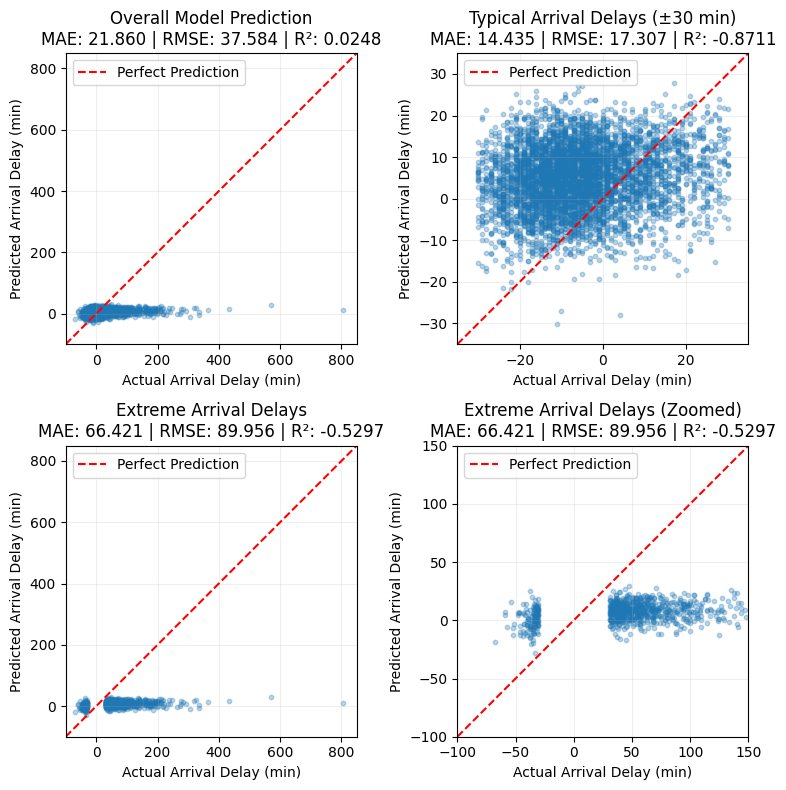

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Select fitted model
model = fitted_models[71]

y_pred, y_actual, y_typical, pred_typical, y_extreme, pred_extreme = model_results(model, X_test, y_test)

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

# 1. Overall model prediction
plot_predictions(
    axes[0, 0],
    y_actual,
    y_pred,
    "Overall Model Prediction"
)

# 2. Typical delays (+/- 30 minutes)
plot_predictions(
    axes[0, 1],
    y_typical,
    pred_typical,
    "Typical Arrival Delays (±30 min)",
    limits=(-35, 35)
)

# 3. Extreme delays
plot_predictions(
    axes[1, 0],
    y_extreme,
    pred_extreme,
    "Extreme Arrival Delays"
)

# 4. Zoomed-in extreme delays
plot_predictions(
    axes[1, 1],
    y_extreme,
    pred_extreme,
    "Extreme Arrival Delays (Zoomed)",
    limits=(-100, 150)
)

plt.tight_layout()
plt.show()

### Polynomial Regression Analysis

To determine whether nonlinear relationships between our numerical features and arrival delays could improve our model's performance, we tested 81 combinations of polynomial degrees ranging from 1 to 3 across our four numerical features.

The table below highlights the three best-performing models based on RMSE.

| Model ID | Departure Time | Arrival Time | Elapsed Time | Distance | MAE | RMSE | R² |
|---|---|---|---|---|---|---|---|
| 71 | 3 | 2 | 3 | 3 | 21.860 | 37.584 | 0.02481 |
| 80 | 3 | 3 | 3 | 3 | 21.860 | 37.584 | 0.02480 |
| 63 | 3 | 2 | 1 | 1 | 21.852 | 37.588 | 0.02461 |

Next, we will investigate whether introducing **interaction terms involving airports** can improve our model's predictive performance. 

In [41]:
airport_interactions = {
    "Origin × Departure Time":
        "C(origin_airport):crs_dep_time_minutes",

    "Origin × Distance":
        "C(origin_airport):distance",

    "Destination × Arrival Time":
        "C(dest_airport_group):scheduled_arrival_minutes",

    "Origin × Destination":
        "C(origin_airport):C(dest_airport_group)"
}

numerical_formula = numerical_features

categorical_formula = [
    f"C({feature})" for feature in categorical_features
]

baseline_formula = (
    TARGET + " ~ " +
    " + ".join(numerical_formula + categorical_formula)
)

In [42]:
results = []
fitted_models = {}

# Baseline + individual interactions
formulas = {"Baseline": baseline_formula}

for name, interaction in airport_interactions.items():
    formulas[name] = baseline_formula + " + " + interaction

# Fit and evaluate each model
for name, formula in formulas.items():

    model = smf.ols(
        formula=formula,
        data=train_df
    ).fit()

    predictions = model.predict(test_df)
    actual = test_df[TARGET]

    results.append({
        "Interaction": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": root_mean_squared_error(actual, predictions),
        "R2": r2_score(actual, predictions),
        "Parameters": len(model.params)
    })

    fitted_models[name] = model

results_df = pd.DataFrame(results)
results_df.sort_values("RMSE")

,Interaction,MAE,RMSE,R2,Parameters
1,Origin × Departure Time,21.804523,37.567483,0.025676,120
2,Origin × Distance,21.875770,37.611771,0.023377,120
0,Baseline,21.869890,37.619184,0.022992,101
3,Destination × Arrival Time,21.897425,37.678428,0.019913,121
4,Origin × Destination,22.338563,38.105412,-0.002426,481


In [43]:
results_df.sort_values("RMSE")

,Interaction,MAE,RMSE,R2,Parameters
1,Origin × Departure Time,21.804523,37.567483,0.025676,120
2,Origin × Distance,21.875770,37.611771,0.023377,120
0,Baseline,21.869890,37.619184,0.022992,101
3,Destination × Arrival Time,21.897425,37.678428,0.019913,121
4,Origin × Destination,22.338563,38.105412,-0.002426,481


In [44]:
airline_interactions = {
    "airline × Departure Time":
        "C(airline):crs_dep_time_minutes",

    "airline × Distance":
        "C(airline):distance",

    "airline × Arrival Time":
        "C(airline):scheduled_arrival_minutes",

    "airline × Destination":
        "C(airline):C(dest_airport_group)"
}

numerical_formula = numerical_features

categorical_formula = [
    f"C({feature})" for feature in categorical_features
]

baseline_formula = (
    TARGET + " ~ " +
    " + ".join(numerical_formula + categorical_formula)
)

In [45]:
results = []
fitted_models = {}

# Baseline + individual interactions
formulas = {"Baseline": baseline_formula}

for name, interaction in airline_interactions.items():
    formulas[name] = baseline_formula + " + " + interaction

# Fit and evaluate each model
for name, formula in formulas.items():

    model = smf.ols(
        formula=formula,
        data=train_df
    ).fit()

    predictions = model.predict(test_df)
    actual = test_df[TARGET]

    results.append({
        "Interaction": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": root_mean_squared_error(actual, predictions),
        "R2": r2_score(actual, predictions),
        "Parameters": len(model.params)
    })

    fitted_models[name] = model

results_df = pd.DataFrame(results)
results_df.sort_values("RMSE")

,Interaction,MAE,RMSE,R2,Parameters
1,airline × Departure Time,21.781384,37.543610,0.026914,124
3,airline × Arrival Time,21.817271,37.566659,0.025719,124
2,airline × Distance,21.874892,37.603903,0.023786,124
0,Baseline,21.869890,37.619184,0.022992,101
4,airline × Destination,22.044791,37.942169,0.006144,561


In [46]:
departure_interactions = {
    "Airline × Departure Time":
        "C(airline):crs_dep_time_minutes",

    "Origin × Departure Time":
        "C(origin_airport):crs_dep_time_minutes",

    "Both Departure Interactions":
        "C(airline):crs_dep_time_minutes"
        " + C(origin_airport):crs_dep_time_minutes"
}
numerical_formula = numerical_features

categorical_formula = [
    f"C({feature})" for feature in categorical_features
]

baseline_formula = TARGET + " ~ " + " + ".join(
    numerical_formula + categorical_formula
)

formulas = {"Baseline": baseline_formula}

for name, interaction in departure_interactions.items():
    formulas[name] = baseline_formula + " + " + interaction




In [47]:
results = []
fitted_models = {}

for name, formula in formulas.items():

    model = smf.ols(
        formula=formula,
        data=train_df
    ).fit()

    predictions = model.predict(test_df)
    actual = test_df[TARGET]

    results.append({
        "Interaction": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": root_mean_squared_error(actual, predictions),
        "R2": r2_score(actual, predictions),
        "Parameters": len(model.params)
    })

    fitted_models[name] = model

results_df = pd.DataFrame(results)

display(results_df.sort_values("RMSE"))

,Interaction,MAE,RMSE,R2,Parameters
3,Both Departure Interactions,21.757941,37.516369,0.028326,143
1,Airline × Departure Time,21.781384,37.543610,0.026914,124
2,Origin × Departure Time,21.804523,37.567483,0.025676,120
0,Baseline,21.869890,37.619184,0.022992,101


In [48]:
from sklearn.model_selection import KFold
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

import statsmodels.formula.api as smf
import pandas as pd
import numpy as np

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

cv_results = []

for name, formula in formulas.items():

    fold_metrics = []

    for train_idx, val_idx in cv.split(train_df):

        # Split training data into folds
        fold_train = train_df.iloc[train_idx]
        fold_val = train_df.iloc[val_idx]

        # Fit model
        model = smf.ols(
            formula=formula,
            data=fold_train
        ).fit()

        # Predict
        predictions = model.predict(fold_val)
        actual = fold_val[TARGET]

        # Store fold metrics
        fold_metrics.append({
            "MAE": mean_absolute_error(actual, predictions),
            "RMSE": root_mean_squared_error(actual, predictions),
            "R2": r2_score(actual, predictions)
        })

    fold_df = pd.DataFrame(fold_metrics)

    # Store average performance and variation
    cv_results.append({
        "Interaction": name,
        "MAE_mean": fold_df["MAE"].mean(),
        "MAE_std": fold_df["MAE"].std(),
        "RMSE_mean": fold_df["RMSE"].mean(),
        "RMSE_std": fold_df["RMSE"].std(),
        "R2_mean": fold_df["R2"].mean(),
        "R2_std": fold_df["R2"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.sort_values("RMSE_mean"))

,Interaction,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
1,Airline × Departure Time,22.555671,0.112328,42.447852,2.681921,0.025033,0.006356
3,Both Departure Interactions,22.580492,0.110119,42.455299,2.675839,0.024674,0.006805
2,Origin × Departure Time,22.614716,0.102089,42.471705,2.673682,0.023916,0.006224
0,Baseline,22.607188,0.118451,42.478747,2.673451,0.023592,0.006034


We have a lot of categorical data so we will use different visual to display each categories relation to arrival_delay

In [49]:
# Save the finalized modelling dataset
model_data.to_parquet(
    "model_data.parquet",
    index=False
)

In [50]:
from sklearn.model_selection import train_test_split
import numpy as np

SEED = 42

# Create a persistent split
train_idx, test_idx = train_test_split(
    np.arange(len(model_data)),
    test_size=0.2,
    random_state=SEED
)

# Save indices
np.savez(
    "model_split.npz",
    train_idx=train_idx,
    test_idx=test_idx
)